/tmp/ipykernel_634/748264879.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=actual_correlations.values, y=actual_correlations.index, palette='coolwarm')


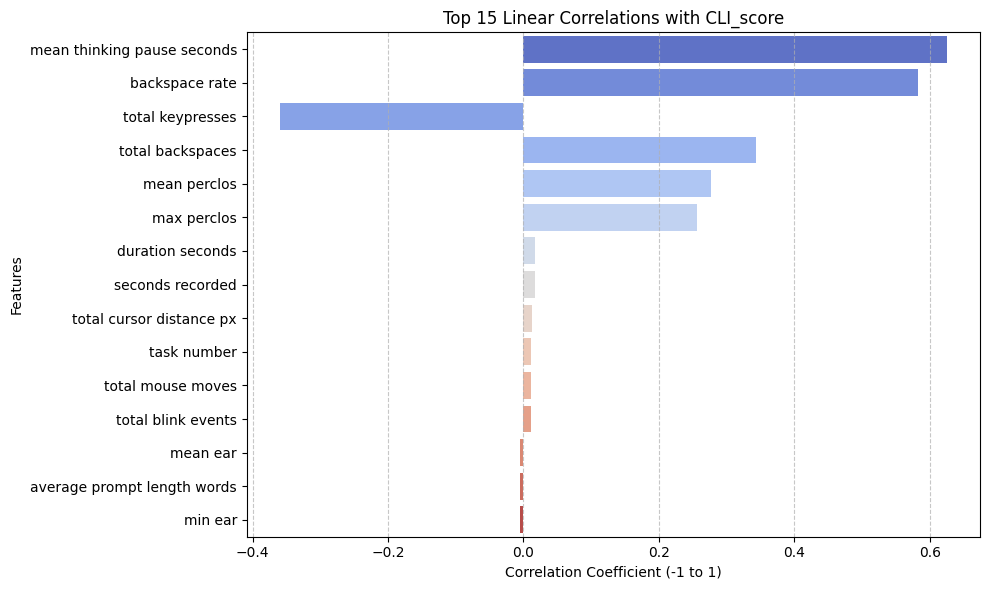

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
df = pd.read_csv('Final_Dataset.csv')

# 2. Basic Cleaning (Impute missing numeric values with median)
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Note: Replace 'CLI_score' below with the actual name of your target column
# if it is already calculated in Final_Dataset.csv.
target_col = 'CLI_score'

# 3. Calculate correlations with the target variable
correlations = df[numeric_cols].corr()[target_col].drop(target_col)
top_correlations = correlations.abs().sort_values(ascending=False).head(15)
actual_correlations = correlations[top_correlations.index]

# 4. Visualize Top 15 Linear Correlations
plt.figure(figsize=(10, 6))
sns.barplot(x=actual_correlations.values, y=actual_correlations.index, palette='coolwarm')
plt.title(f'Top 15 Linear Correlations with {target_col}')
plt.xlabel('Correlation Coefficient (-1 to 1)')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_634/703204782.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=actual_correlations.values, y=actual_correlations.index, palette='coolwarm')


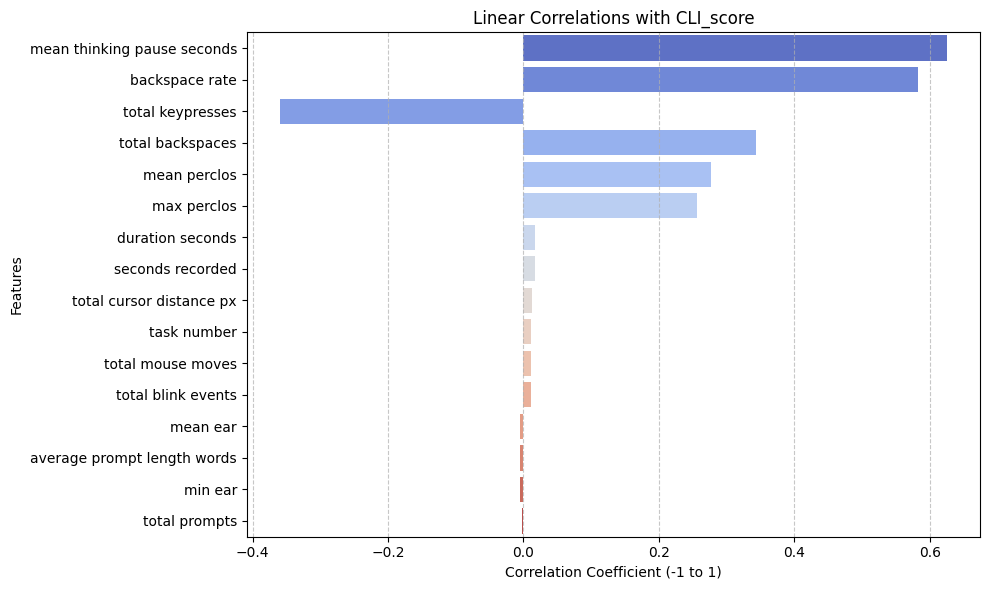

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Final_Dataset.csv')

# 2. Select Target and Numeric Columns
target_col = 'CLI_score'
numeric_cols = df.select_dtypes(include=[np.number]).columns

# 3. Calculate correlations with the target variable
correlations = df[numeric_cols].corr()[target_col].drop(target_col)
top_correlations = correlations.abs().sort_values(ascending=False)
actual_correlations = correlations[top_correlations.index]

# 4. Visualize Correlations
plt.figure(figsize=(10, 6))
sns.barplot(x=actual_correlations.values, y=actual_correlations.index, palette='coolwarm')
plt.title(f'Linear Correlations with {target_col}')
plt.xlabel('Correlation Coefficient (-1 to 1)')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv('Final_Dataset.csv')

# 2. Check Shape, Missing Values, and Duplicates
print("--- DATASET INTEGRITY ---")
print(f"Total Rows: {len(df)}")
print(f"Total Columns: {len(df.columns)}")
print(f"Missing Values: {df.isna().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

# 3. Check Categorical Distributions (Ensuring balanced synthetic classes)
print("\n--- CATEGORICAL DISTRIBUTIONS ---")
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if col not in ['participant id', 'question id']: # Skip IDs
        print(f"{col}:\n{df[col].value_counts(normalize=True).round(3)}\n")

# 4. Check Numerical Statistics (Ensuring realistic bounds and no zero-variance columns)
print("--- NUMERICAL STATISTICS ---")
num_stats = df.describe().T[['mean', 'std', 'min', 'max']]
print(num_stats)

--- DATASET INTEGRITY ---
Total Rows: 12000
Total Columns: 23
Missing Values: 0
Duplicate Rows: 0

--- CATEGORICAL DISTRIBUTIONS ---
dominant gaze:
dominant gaze
left      0.258
down      0.252
right     0.248
center    0.242
Name: proportion, dtype: float64

dominant fatigue:
dominant fatigue
medium    0.334
low       0.334
high      0.333
Name: proportion, dtype: float64

dominant emotion:
dominant emotion
happy         0.253
focused       0.251
neutral       0.249
frustrated    0.248
Name: proportion, dtype: float64

CLI_label:
CLI_label
High                    0.318
Moderate                0.311
Very High / Overload    0.236
Low                     0.135
Name: proportion, dtype: float64

--- NUMERICAL STATISTICS ---
                                     mean          std        min         max
task number                      1.999750     0.816582     1.0000      3.0000
seconds recorded                98.577618    38.502000    29.8800    175.8300
duration seconds               107.7

Training XGBoost Regressor...
Calculating feature importance...


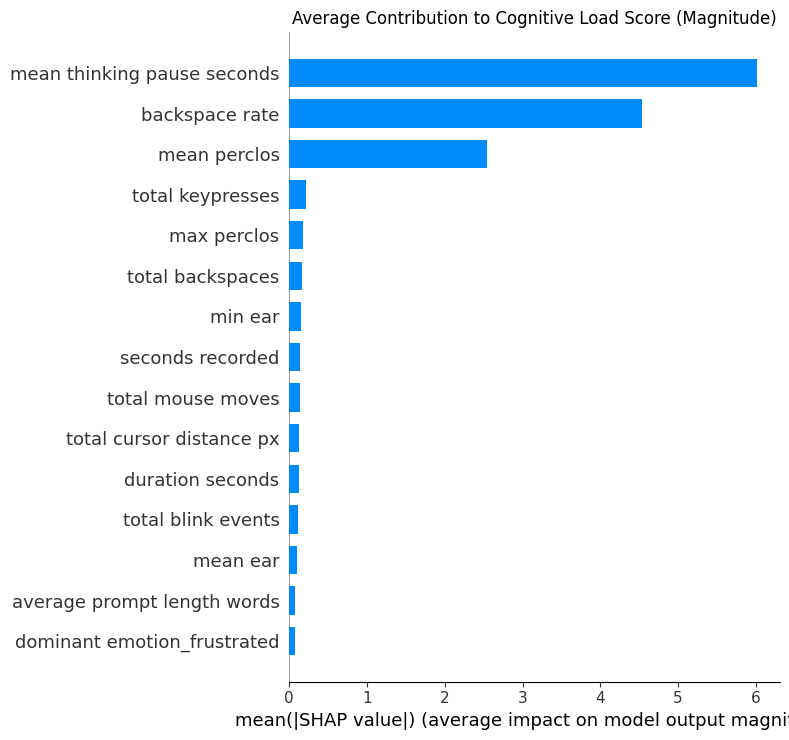

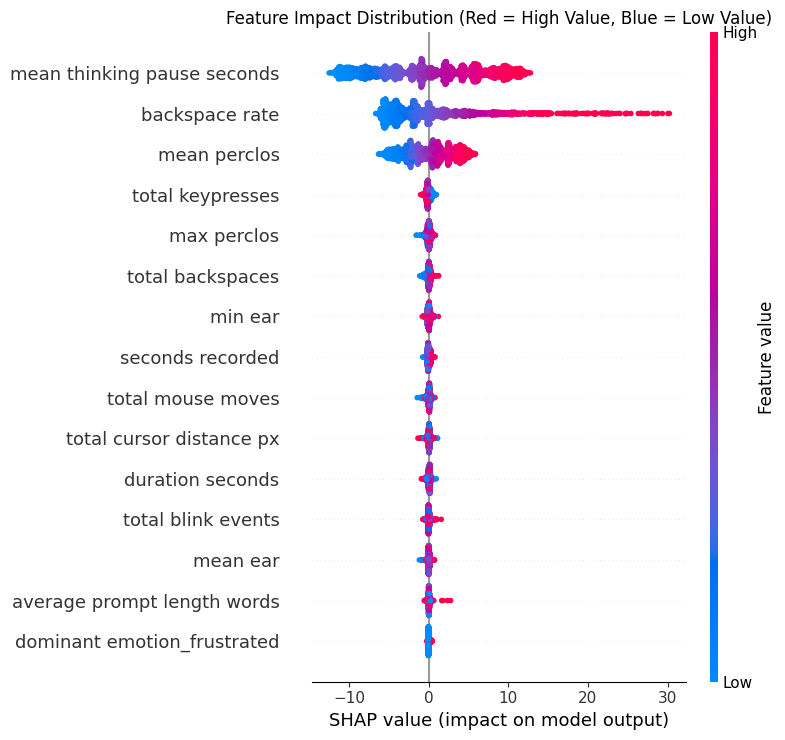

In [ ]:
!pip install shap -q
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# 1. Prepare Features (X) and Target (y)
# Drop IDs, meta-columns, and the target labels from the input features
cols_to_drop = ['participant id', 'question id', 'CLI_score', 'CLI_label']
X = df.drop(columns=cols_to_drop)

# One-hot encode the categorical columns (dominant gaze, fatigue, emotion)
X = pd.get_dummies(X, drop_first=True)
y = df['CLI_score']

# 2. Train/Test Split & Scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# 3. Train the Model
print("Training XGBoost Regressor...")
model = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
model.fit(X_train_scaled, y_train)

# 4. Calculate SHAP values
print("Calculating feature importance...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_df)

# 5. Visual 1: Average Magnitude of Contribution
plt.figure(figsize=(10, 6))
plt.title("Average Contribution to Cognitive Load Score (Magnitude)")
shap.summary_plot(shap_values, X_test_df, plot_type="bar", max_display=15)

# 6. Visual 2: Directional Impact
plt.figure(figsize=(10, 6))
plt.title("Feature Impact Distribution (Red = High Value, Blue = Low Value)")
shap.summary_plot(shap_values, X_test_df, max_display=15)

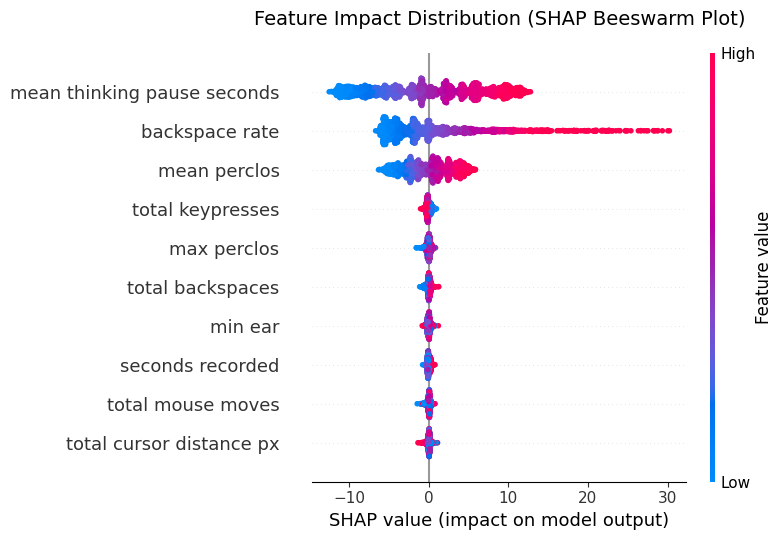

In [ ]:
import matplotlib.pyplot as plt

# Generate the SHAP Beeswarm Plot (Directional Impact)
plt.figure(figsize=(10, 8))
plt.title("Feature Impact Distribution (SHAP Beeswarm Plot)", pad=20, fontsize=14)

# This creates the dot-based plot showing high vs low values
shap.summary_plot(shap_values, X_test_df, max_display=10)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report
from xgboost import XGBRegressor

# 1. Load and Prepare Data
df = pd.read_csv('Final_Dataset.csv')

# Drop non-predictive metadata and target columns
X = df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X = pd.get_dummies(X, drop_first=True) # One-hot encode categoricals

# Target variable (Train to predict the continuous score, not the label)
y = df['CLI_score']

# 2. Train/Test Split (80% Training, 20% Unseen Evaluation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Build the ML Pipeline
# A pipeline guarantees that scaling is applied sequentially, preventing data leakage
# from the test set into the training calculations.
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', XGBRegressor(random_state=42, n_jobs=-1))
])

# 4. Define the Hyperparameter Grid
# Instead of guessing the best settings, GridSearchCV tests all combinations below
# to find the absolute maximum realistic accuracy for your specific dataset.
param_grid = {
    'model__n_estimators': [200, 400, 600],       # Number of decision trees
    'model__max_depth': [4, 5, 6],                # How complex each tree can get
    'model__learning_rate': [0.01, 0.05, 0.1],    # How aggressively the model corrects errors
    'model__subsample': [0.8, 1.0]                # Percentage of data used per tree (prevents overfitting)
}

# 5. Execute Grid Search with Cross-Validation (K=5)
print("Initiating Pipeline Training and Grid Search...")
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1
)

grid_search.fit(X_train, y_train)

# 6. Extract the Best Model
best_pipeline = grid_search.best_estimator_
print(f"\\nBest Hyperparameters Found: {grid_search.best_params_}")

# 7. Evaluate on Unseen Test Data (Continuous Score)
predictions = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print("\\n--- FINAL PIPELINE REGRESSION METRICS ---")
print(f"R-squared (R2): {r2:.3f}")
print(f"Mean Absolute Error (MAE): {mae:.2f} points")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} points")

# 8. Evaluate Business Logic (Categorical Buckets)
# Map the highly-accurate continuous predictions back to your predefined business rules
def categorize_load(score):
    if score < 40: return 'Low'
    elif score < 60: return 'Moderate'
    elif score < 75: return 'High'
    else: return 'Very High / Overload'

predicted_labels = pd.Series(predictions).apply(categorize_load)
actual_labels = y_test.apply(categorize_load)

order = ['Low', 'Moderate', 'High', 'Very High / Overload']
print("\\n--- FINAL PIPELINE CLASSIFICATION METRICS ---")
print(classification_report(actual_labels, predicted_labels, labels=order, zero_division=0))

Initiating Pipeline Training and Grid Search...
Fitting 5 folds for each of 54 candidates, totalling 270 fits
\nBest Hyperparameters Found: {'model__learning_rate': 0.01, 'model__max_depth': 4, 'model__n_estimators': 600, 'model__subsample': 0.8}
\n--- FINAL PIPELINE REGRESSION METRICS ---
R-squared (R2): 0.802
Mean Absolute Error (MAE): 4.00 points
Root Mean Squared Error (RMSE): 4.99 points
\n--- FINAL PIPELINE CLASSIFICATION METRICS ---
                      precision    recall  f1-score   support

                 Low       0.75      0.49      0.59       243
            Moderate       0.82      0.89      0.85      1445
                High       0.77      0.71      0.74       624
Very High / Overload       0.82      0.75      0.79        88

            accuracy                           0.80      2400
           macro avg       0.79      0.71      0.74      2400
        weighted avg       0.80      0.80      0.79      2400



In [ ]:
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from google.colab import files

# 1. Load and prepare the data
df = pd.read_csv('Final_Dataset.csv')
X = df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X = pd.get_dummies(X, drop_first=True)
y = df['CLI_score']

# 2. Build the final production pipeline
# (This ensures any future data fed to the model is scaled automatically)
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.01, subsample=0.8, random_state=42))
])

# 3. Train on ALL available data
print("Training final production pipeline...")
final_pipeline.fit(X, y)

# 4. Save the pipeline to a file
model_filename = 'cognitive_load_pipeline.joblib'
joblib.dump(final_pipeline, model_filename)
print(f"Model successfully saved as: {model_filename}")

# 5. Trigger the download to your local machine
files.download(model_filename)

Training final production pipeline...
Model successfully saved as: cognitive_load_pipeline.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--- TOP 10 FEATURE WEIGHTS: EMPIRICAL ML vs THEORETICAL FORMULA ---
                    Feature  Empirical_Weight_Pct  Theoretical_Weight_Pct
mean thinking pause seconds             43.919998                    3.00
             backspace rate             31.730000                    7.00
               mean perclos              9.480000                   10.50
                max perclos              3.240000                    4.50
           total keypresses              0.860000                    3.00
           total backspaces              0.750000                    0.00
           duration seconds              0.690000                    0.00
    dominant fatigue_medium              0.690000                    0.00
          total mouse moves              0.640000                    2.25
   total cursor distance px              0.620000                    0.00


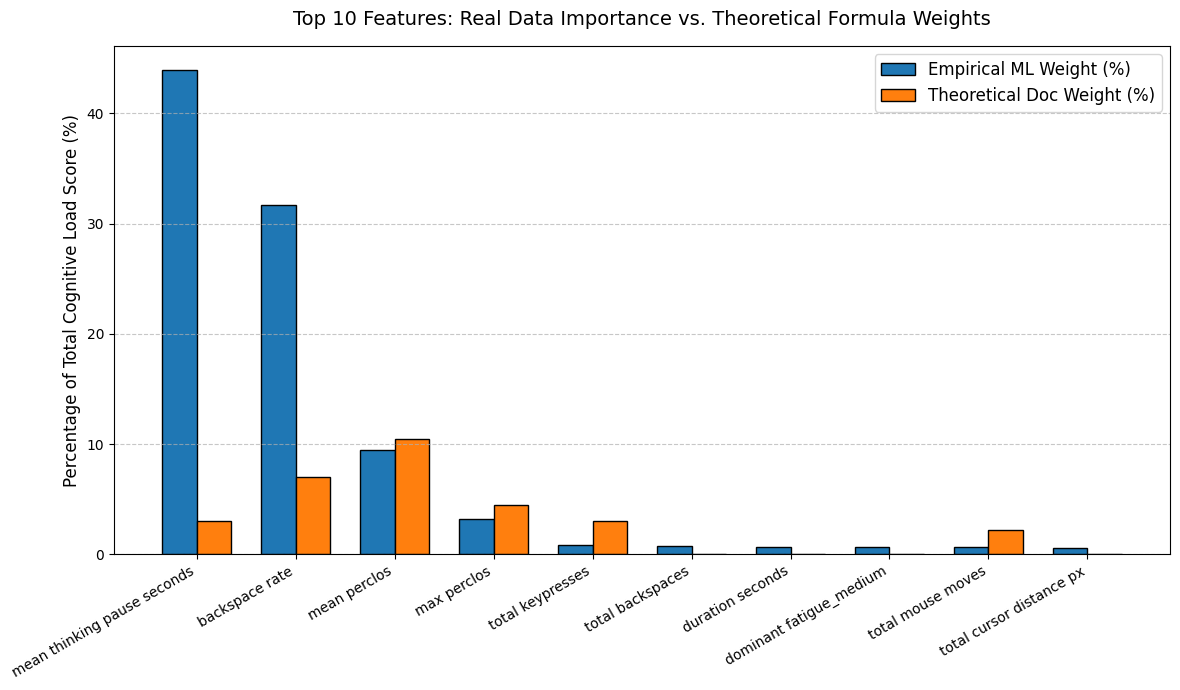

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# 1. Load the dataset
df = pd.read_csv('Final_Dataset.csv')
X = df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X = pd.get_dummies(X, drop_first=True)
y = df['CLI_score']

# 2. Train the XGBoost Model to get empirical weights
model = XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.01, subsample=0.8, random_state=42)
model.fit(X, y)
empirical_weights = (model.feature_importances_ / model.feature_importances_.sum()) * 100

weights_df = pd.DataFrame({
    'Feature': X.columns,
    'Empirical_Weight_Pct': empirical_weights
})

# 3. Map Theoretical Weights derived from the source document formulas
# If a feature is not mapped, its theoretical weight defaults to 0%
theoretical_mapping = {
    'mean thinking pause seconds': 3.0,  # M_pause: 15% (M) * 20% = 3.0%
    'backspace rate': 7.0,               # M_corr (3%) + P_error (4%) = 7.0%
    'mean perclos': 10.5,                # E_pupil: 30% (E) * 35% = 10.5%
    'total keypresses': 3.0,             # P_completion: 20% (P) * 15% = 3.0%
    'max perclos': 4.5,                  # E_blink: 30% (E) * 15% = 4.5%
    'dominant emotion_frustrated': 3.0,  # F_frustration: 10% (F) * 30% = 3.0%
    'total mouse moves': 2.25,           # M_trajectory: 15% (M) * 15% = 2.25%
    'mean ear': 3.0,                     # E_gaze (approx): 30% (E) * 10% = 3.0%
    'min ear': 3.0,                      # E_saccade (approx): 30% (E) * 10% = 3.0%
    'total blink events': 4.5,           # E_blink: 30% (E) * 15% = 4.5%
}

weights_df['Theoretical_Weight_Pct'] = weights_df['Feature'].map(theoretical_mapping).fillna(0)

# 4. Sort and select the Top 10 Features based on Empirical ML Importance
top_10_df = weights_df.sort_values('Empirical_Weight_Pct', ascending=False).head(10)

print("--- TOP 10 FEATURE WEIGHTS: EMPIRICAL ML vs THEORETICAL FORMULA ---")
print(top_10_df.round(2).to_string(index=False))

# 5. Visualize the Discrepancy
fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(top_10_df['Feature']))
width = 0.35

ax.bar(x - width/2, top_10_df['Empirical_Weight_Pct'], width, label='Empirical ML Weight (%)', color='#1f77b4', edgecolor='black')
ax.bar(x + width/2, top_10_df['Theoretical_Weight_Pct'], width, label='Theoretical Doc Weight (%)', color='#ff7f0e', edgecolor='black')

ax.set_ylabel('Percentage of Total Cognitive Load Score (%)', fontsize=12)
ax.set_title('Top 10 Features: Real Data Importance vs. Theoretical Formula Weights', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(top_10_df['Feature'], rotation=30, ha='right', fontsize=10)
ax.legend(fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load data and completely drop the predefined scores (Unsupervised Mode)
df = pd.read_csv('Final_Dataset.csv')
X = df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X = pd.get_dummies(X, drop_first=True)

# 2. Standardization is CRITICAL for unsupervised learning
# We must put backspaces and pause seconds on the same mathematical scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA to find the strongest underlying behavioral index
pca = PCA(n_components=1)
pca.fit(X_scaled)

# 4. Extract the weights (loadings) of the first principal component
# We take the absolute values because we care about the magnitude of influence
raw_weights = np.abs(pca.components_[0])

# 5. Normalize the weights so they sum to 100 (creating a clear percentage formula)
normalized_weights = (raw_weights / raw_weights.sum()) * 100

# 6. Create a readable DataFrame and generate the formula string
formula_df = pd.DataFrame({
    'Feature': X.columns,
    'Unsupervised_Weight_Pct': normalized_weights
}).sort_values('Unsupervised_Weight_Pct', ascending=False)

print("--- UNSUPERVISED DATA-DRIVEN FORMULA WEIGHTS ---")
print(formula_df.head(10).round(2).to_string(index=False))

# 7. Construct the final mathematical formula string for the top 5 features
top_5 = formula_df.head(5)
formula_parts = [f"{row['Unsupervised_Weight_Pct']:.1f}*({row['Feature']})" for _, row in top_5.iterrows()]
custom_formula = " + ".join(formula_parts)

print("\n--- YOUR NEW CUSTOM COGNITIVE LOAD INDEX ---")
print(f"Index = {custom_formula} ...")

--- UNSUPERVISED DATA-DRIVEN FORMULA WEIGHTS ---
                    Feature  Unsupervised_Weight_Pct
           seconds recorded                    33.03
           duration seconds                    33.02
             backspace rate                     5.98
                    min ear                     5.34
                   mean ear                     5.17
           total keypresses                     4.37
           total backspaces                     4.09
                max perclos                     1.74
               mean perclos                     1.71
dominant emotion_frustrated                     0.84

--- YOUR NEW CUSTOM COGNITIVE LOAD INDEX ---
Index = 33.0*(seconds recorded) + 33.0*(duration seconds) + 6.0*(backspace rate) + 5.3*(min ear) + 5.2*(mean ear) ...


In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load data
df = pd.read_csv('Final_Dataset.csv')

# 2. Drop scores AND the distracting time metrics
cols_to_drop = ['participant id', 'question id', 'CLI_score', 'CLI_label',
                'seconds recorded', 'duration seconds']
X = df.drop(columns=cols_to_drop)
X = pd.get_dummies(X, drop_first=True)

# 3. Standardize the data so all features are on the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Run PCA to extract the primary behavioral variance (Component 1)
pca = PCA(n_components=1)
pca.fit(X_scaled)

# 5. Extract and normalize the weights to create a percentage-based formula
raw_weights = np.abs(pca.components_[0])
normalized_weights = (raw_weights / raw_weights.sum()) * 100

formula_df = pd.DataFrame({
    'Feature': X.columns,
    'Weight_Pct': normalized_weights
}).sort_values('Weight_Pct', ascending=False)

print("--- ADJUSTED PCA FORMULA WEIGHTS (TIME REMOVED) ---")
print(formula_df.head(10).round(2).to_string(index=False))

# 6. Print the mathematical formula
top_5 = formula_df.head(5)
formula_parts = [f"{row['Weight_Pct']:.1f}*({row['Feature']})" for _, row in top_5.iterrows()]
custom_formula = " + ".join(formula_parts)

print("\n--- YOUR NEW BEHAVIORAL COGNITIVE LOAD INDEX ---")
print(f"Index = {custom_formula} ...")

--- ADJUSTED PCA FORMULA WEIGHTS (TIME REMOVED) ---
                 Feature  Weight_Pct
                 min ear       27.01
                mean ear       26.99
            mean perclos        9.67
             max perclos        9.61
          backspace rate        8.70
        total backspaces        6.75
        total keypresses        5.30
 dominant fatigue_medium        1.01
total cursor distance px        0.98
      dominant gaze_down        0.81

--- YOUR NEW BEHAVIORAL COGNITIVE LOAD INDEX ---
Index = 27.0*(min ear) + 27.0*(mean ear) + 9.7*(mean perclos) + 9.6*(max perclos) + 8.7*(backspace rate) ...


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load data
df = pd.read_csv('Final_Dataset.csv')

# 2. Isolate purely behavioral features (dropping ID, scores, and time)
cols_to_drop = ['participant id', 'question id', 'CLI_score', 'CLI_label',
                'seconds recorded', 'duration seconds']
X = df.drop(columns=cols_to_drop)
X = pd.get_dummies(X, drop_first=True)

# 3. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Tell K-Means to find exactly 4 natural groups
print("Grouping users into 4 behavioral clusters...")
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Behavior_Cluster'] = kmeans.fit_predict(X_scaled)

# 5. Analyze what each cluster actually represents
# We calculate the average behavior for the people assigned to each group
cluster_summary = df.groupby('Behavior_Cluster').agg(
    Avg_Pause_Seconds=('mean thinking pause seconds', 'mean'),
    Avg_Backspace_Rate=('backspace rate', 'mean'),
    Avg_Total_Keys=('total keypresses', 'mean'),
    Avg_Original_CLI=('CLI_score', 'mean'), # Just to see how the cluster aligns with your original labels
    User_Count=('CLI_score', 'count')
).round(2)

print("\n--- BEHAVIORAL TRIBE SUMMARY ---")
print(cluster_summary)

Grouping users into 4 behavioral clusters...

--- BEHAVIORAL TRIBE SUMMARY ---
                  Avg_Pause_Seconds  Avg_Backspace_Rate  Avg_Total_Keys  \
Behavior_Cluster                                                          
0                              9.88                0.12          253.81   
1                             10.15                0.50          100.35   
2                             10.18                0.14          240.23   
3                              9.73                0.14          236.59   

                  Avg_Original_CLI  User_Count  
Behavior_Cluster                                
0                            51.55        4845  
1                            66.70        1702  
2                            52.74        2750  
3                            52.40        2703  


=== 1. DERIVED UNSUPERVISED FORMULA WEIGHTS ===
                    Feature Modality  Unsupervised_Formula_Weight (%)
                    min ear   Ocular                            24.75
                   mean ear   Ocular                            24.74
mean thinking pause seconds Behavior                            17.03
             backspace rate Behavior                            12.13
average prompt length words Behavior                            11.76
                max perclos   Ocular                             4.80
               mean perclos   Ocular                             4.79

=== 2. BLIND VALIDATION AGAINST GROUND TRUTH ===
Spearman Rank Correlation with original CLI_score: 0.340

=== 3. DISCOVERED GMM CLUSTERS PROFILE ===
                      Count  Pause_Sec  Backspace_Rate  Mean_PERCLOS  \
Cluster 0 (Flow/Low)   3179       7.11            0.13          0.19   
Cluster 1 (Moderate)   2755      12.80            0.24          0.19   
Cluster 2 (High)       31

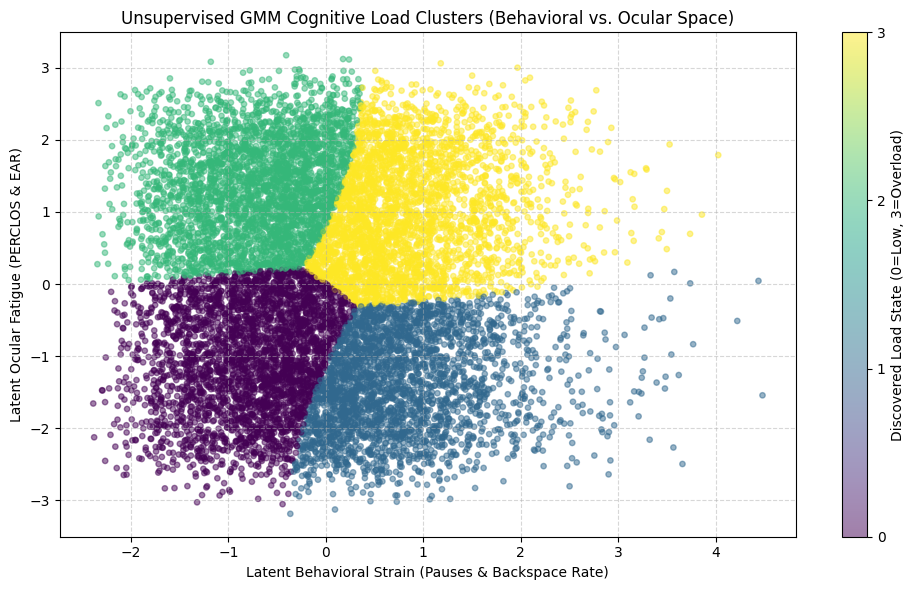

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from scipy.stats import spearmanr

# 1. Load Data
df = pd.read_csv('Final_Dataset.csv')

# 2. Group ONLY Intensity/State Features by Modality (Drop raw volume & time)
behavior_cols = ['mean thinking pause seconds', 'backspace rate', 'average prompt length words']
ocular_cols = ['mean perclos', 'max perclos', 'min ear', 'mean ear']

scaler = StandardScaler()
X_behav_scaled = scaler.fit_transform(df[behavior_cols])
X_ocular_scaled = scaler.fit_transform(df[ocular_cols])

# 3. Stage 1: Modality-Specific PCA
pca_behav = PCA(n_components=1, random_state=42)
behav_latent = pca_behav.fit_transform(X_behav_scaled).flatten()

pca_ocular = PCA(n_components=1, random_state=42)
ocular_latent = pca_ocular.fit_transform(X_ocular_scaled).flatten()

# Fix Sign Ambiguity: Ensure higher latent score = higher strain
if np.corrcoef(behav_latent, df['backspace rate'])[0, 1] < 0:
    behav_latent *= -1
    pca_behav.components_[0] *= -1

if np.corrcoef(ocular_latent, df['mean perclos'])[0, 1] < 0:
    ocular_latent *= -1
    pca_ocular.components_[0] *= -1

# 4. Stage 2: Combine Modalities into a 0-100 Unsupervised CLI
# Weighting modalities proportional to the variance they explain
w_b = pca_behav.explained_variance_ratio_[0]
w_o = pca_ocular.explained_variance_ratio_[0]
total_var = w_b + w_o

raw_unsupervised_index = (w_b / total_var) * behav_latent + (w_o / total_var) * ocular_latent

# Scale to 0-100 to match CLI_score format
minmax = MinMaxScaler(feature_range=(0, 100))
df['Unsupervised_CLI'] = minmax.fit_transform(raw_unsupervised_index.reshape(-1, 1))

# 5. Soft Clustering via Gaussian Mixture Model (GMM)
X_combined_strain = np.column_stack([behav_latent, ocular_latent])
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
raw_clusters = gmm.fit_predict(X_combined_strain)

# Sort cluster IDs (0, 1, 2, 3) from lowest strain to highest strain automatically
cluster_means = pd.Series(df['Unsupervised_CLI']).groupby(raw_clusters).mean().sort_values()
cluster_map = {old_id: new_id for new_id, old_id in enumerate(cluster_means.index)}
df['Unsupervised_Cluster'] = pd.Series(raw_clusters).map(cluster_map)

# 6. Print Derived Unsupervised Weights
behav_weights = (np.abs(pca_behav.components_[0]) / np.abs(pca_behav.components_[0]).sum()) * (w_b / total_var) * 100
ocular_weights = (np.abs(pca_ocular.components_[0]) / np.abs(pca_ocular.components_[0]).sum()) * (w_o / total_var) * 100

weights_summary = pd.DataFrame({
    'Feature': behavior_cols + ocular_cols,
    'Modality': ['Behavior']*len(behavior_cols) + ['Ocular']*len(ocular_cols),
    'Unsupervised_Formula_Weight (%)': np.concatenate([behav_weights, ocular_weights])
}).sort_values('Unsupervised_Formula_Weight (%)', ascending=False)

print("=== 1. DERIVED UNSUPERVISED FORMULA WEIGHTS ===")
print(weights_summary.round(2).to_string(index=False))

# 7. Post-Hoc Validation (Checking against hidden Ground Truth)
corr, _ = spearmanr(df['Unsupervised_CLI'], df['CLI_score'])
print(f"\n=== 2. BLIND VALIDATION AGAINST GROUND TRUTH ===")
print(f"Spearman Rank Correlation with original CLI_score: {corr:.3f}")

cluster_profile = df.groupby('Unsupervised_Cluster').agg(
    Count=('CLI_score', 'count'),
    Pause_Sec=('mean thinking pause seconds', 'mean'),
    Backspace_Rate=('backspace rate', 'mean'),
    Mean_PERCLOS=('mean perclos', 'mean'),
    Unsup_CLI=('Unsupervised_CLI', 'mean'),
    Actual_CLI_Score=('CLI_score', 'mean')
).round(2)

cluster_profile.index = ['Cluster 0 (Flow/Low)', 'Cluster 1 (Moderate)', 'Cluster 2 (High)', 'Cluster 3 (Overload)']
print("\n=== 3. DISCOVERED GMM CLUSTERS PROFILE ===")
print(cluster_profile)

# 8. Plot the Discovered Clusters in 2D Strain Space
plt.figure(figsize=(10, 6))
scatter = plt.scatter(behav_latent, ocular_latent, c=df['Unsupervised_Cluster'], cmap='viridis', alpha=0.5, s=15)
plt.colorbar(scatter, ticks=[0, 1, 2, 3], label='Discovered Load State (0=Low, 3=Overload)')
plt.xlabel('Latent Behavioral Strain (Pauses & Backspace Rate)')
plt.ylabel('Latent Ocular Fatigue (PERCLOS & EAR)')
plt.title('Unsupervised GMM Cognitive Load Clusters (Behavioral vs. Ocular Space)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import spearmanr

# 1. Load Data and drop any rows where target labels themselves might be missing
df = pd.read_csv('Final_Dataset.csv').dropna(subset=['CLI_score', 'CLI_label']).reset_index(drop=True)
X_encoded = pd.get_dummies(df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label']), drop_first=False)

# 2. Define the Complete 3-Modality Feature Set (Behavior + Ocular + Facial)
behavior_cols = ['mean thinking pause seconds', 'backspace rate', 'average prompt length words', 'total blink events']
ocular_cols = ['mean perclos', 'max perclos', 'min ear', 'mean ear']
facial_cols = [c for c in X_encoded.columns if 'frustrated' in c or 'angry' in c or 'sad' in c or 'emotion' in c]

# Keep only valid columns present in X_encoded
behavior_cols = [c for c in behavior_cols if c in X_encoded.columns]
ocular_cols = [c for c in ocular_cols if c in X_encoded.columns]

# 3. Impute Missing Values (NaNs) & Standardize
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_B_clean = imputer.fit_transform(X_encoded[behavior_cols])
X_E_clean = imputer.fit_transform(X_encoded[ocular_cols])
X_F_clean = imputer.fit_transform(X_encoded[facial_cols])

X_B = scaler.fit_transform(X_B_clean)
X_E = scaler.fit_transform(X_E_clean)
X_F = scaler.fit_transform(X_F_clean)

# 4. Extract Latent Strain for Each Modality via PCA
pca_B = PCA(n_components=1, random_state=42).fit(X_B)
latent_B = pca_B.transform(X_B).flatten()
if np.corrcoef(latent_B, X_B_clean[:, behavior_cols.index('backspace rate')])[0, 1] < 0:
    latent_B *= -1

pca_E = PCA(n_components=1, random_state=42).fit(X_E)
latent_E = pca_E.transform(X_E).flatten()
if np.corrcoef(latent_E, X_E_clean[:, ocular_cols.index('mean perclos')])[0, 1] < 0:
    latent_E *= -1

pca_F = PCA(n_components=1, random_state=42).fit(X_F)
latent_F = pca_F.transform(X_F).flatten()
frust_col = [i for i, c in enumerate(facial_cols) if 'frustrated' in c]
if frust_col and np.corrcoef(latent_F, X_F_clean[:, frust_col[0]])[0, 1] < 0:
    latent_F *= -1

# 5. Fit Unsupervised GMM on the 3D Modality Space
X_3D_space = np.column_stack([latent_B, latent_E, latent_F])
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
clusters = gmm.fit_predict(X_3D_space)

# Create continuous Unsupervised Target from variance-weighted modalities
vars_explained = np.array([pca_B.explained_variance_ratio_[0],
                           pca_E.explained_variance_ratio_[0],
                           pca_F.explained_variance_ratio_[0]])
modality_weights = vars_explained / vars_explained.sum()

raw_unsup_score = (modality_weights[0] * latent_B +
                   modality_weights[1] * latent_E +
                   modality_weights[2] * latent_F)
unsup_cli_target = MinMaxScaler((0, 100)).fit_transform(raw_unsup_score.reshape(-1, 1)).flatten()

# 6. BACKTRACKING: Derive Explicit Normalized Formula via Surrogate Regression
all_selected_cols = behavior_cols + ocular_cols + facial_cols
X_all_clean = imputer.fit_transform(X_encoded[all_selected_cols])
X_norm_0_1 = MinMaxScaler((0, 1)).fit_transform(X_all_clean)

# Fit positive linear regression to distill exact weights
surrogate = LinearRegression(positive=True)
surrogate.fit(X_norm_0_1, unsup_cli_target)

derived_weights = (surrogate.coef_ / surrogate.coef_.sum()) * 100
formula_table = pd.DataFrame({
    'Feature': all_selected_cols,
    'Derived_Weight_Pct': derived_weights
}).sort_values('Derived_Weight_Pct', ascending=False)

print("=== 1. BACKTRACKED DATA-DRIVEN FORMULA WEIGHTS ===")
print(formula_table.round(2).to_string(index=False))

# Print clean equation for top features
top_eq = [f"{r['Derived_Weight_Pct']:.1f}*({r['Feature']})" for _, r in formula_table.head(6).iterrows() if r['Derived_Weight_Pct'] > 0]
print(f"\nVerified Formula:\nCLI_Unsup = " + " + ".join(top_eq))

# 7. UNSUPERVISED EVALUATION METRICS
sil_score = silhouette_score(X_3D_space, clusters, sample_size=3000, random_state=42)
db_index = davies_bouldin_score(X_3D_space, clusters)
ari_score = adjusted_rand_score(df['CLI_label'], clusters)
rank_corr, _ = spearmanr(unsup_cli_target, df['CLI_score'])

print("\n=== 2. UNSUPERVISED MODEL EVALUATION METRICS ===")
print(f"Silhouette Score (Cluster Separation, higher is better): {sil_score:.3f}")
print(f"Davies-Bouldin Index (Cluster Compactness, lower is better): {db_index:.3f}")
print(f"Spearman Correlation with Reference CLI_score: {rank_corr:.3f}")
print(f"Adjusted Rand Index (Agreement with CLI_label): {ari_score:.3f}")

=== 1. BACKTRACKED DATA-DRIVEN FORMULA WEIGHTS ===
                    Feature  Derived_Weight_Pct
                    min ear               19.56
                   mean ear               15.35
   dominant emotion_focused               13.31
             backspace rate               11.98
   dominant emotion_neutral               10.84
dominant emotion_frustrated               10.14
mean thinking pause seconds                8.58
                max perclos                4.04
         total blink events                3.30
               mean perclos                2.91
average prompt length words                0.00
     dominant emotion_happy                0.00

Verified Formula:
CLI_Unsup = 19.6*(min ear) + 15.3*(mean ear) + 13.3*(dominant emotion_focused) + 12.0*(backspace rate) + 10.8*(dominant emotion_neutral) + 10.1*(dominant emotion_frustrated)

=== 2. UNSUPERVISED MODEL EVALUATION METRICS ===
Silhouette Score (Cluster Separation, higher is better): 0.328
Davies-Bouldin Inde

=== 1. CALCULATED MODALITY SUB-SCORES (0 to 1 SCALE) ===
      E_score  F_score  M_score  N_score  P_score
mean    0.500    0.375    0.499    0.499    0.498
std     0.099    0.071    0.100    0.069    0.105
min     0.234    0.198    0.254    0.301    0.253
max     0.802    0.591    0.801    0.770    0.895

=== 2. FORMULA COMPARISON WITH DATASET CLI_score ===
Pearson Correlation (r):   0.774
Spearman Rank Corr (rho):  0.756
Mean Absolute Difference:  11.84 points

=== 3. SAMPLE ROW-BY-ROW CALCULATION ===
 E_score  F_score  M_score  P_score  Calculated_Doc_CLI  CLI_score Calculated_Doc_Label
    0.39     0.29     0.50     0.65               41.83      61.69             Moderate
    0.32     0.27     0.32     0.45               11.74      37.60                  Low
    0.55     0.40     0.46     0.49               45.58      54.55             Moderate
    0.44     0.31     0.61     0.53               44.35      64.02             Moderate
    0.59     0.37     0.53     0.49               5

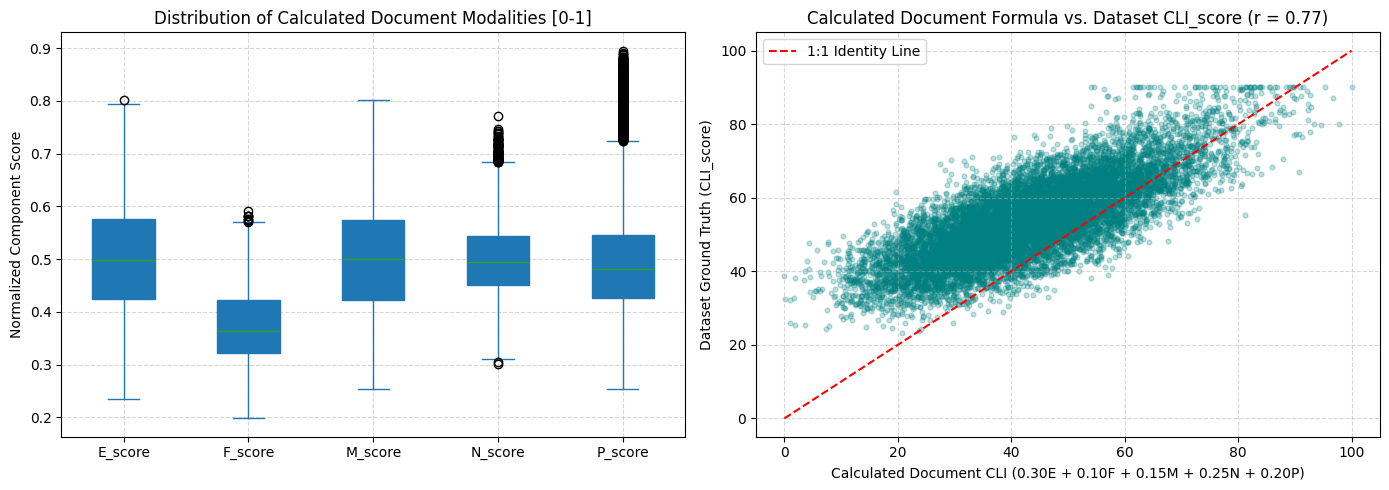

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Load Data
df = pd.read_csv('Final_Dataset.csv').dropna(subset=['CLI_score']).reset_index(drop=True)
df_enc = pd.get_dummies(df, drop_first=False)

# Helper: Document's exact Z-score clipping & [0, 1] normalization (Section 2A)
def norm_z_01(series, invert=False):
    s = pd.Series(series).fillna(pd.Series(series).median())
    std = s.std()
    if std == 0:
        return np.zeros(len(s))
    z = np.clip((s - s.mean()) / std, -3, 3)
    if invert:
        z = -z  # Used when lower raw values mean higher cognitive load (e.g., EAR, Accuracy)
    return (z + 3) / 6.0

# Helper: Safely fetch column or fallback to zeros
def get_col(name, default_val=0.0):
    return df_enc[name] if name in df_enc.columns else pd.Series(default_val, index=df.index)

dur_sec = np.maximum(get_col('duration seconds', 60.0), 1.0)
dur_min = dur_sec / 60.0

# =========================================================================
# SECTION 2: EYE-TRACKING COMPONENT (E)
# E = 0.35*E_pupil + 0.30*E_fix + 0.15*E_blink + 0.10*E_saccade + 0.10*E_gaze
# =========================================================================
E_pupil   = norm_z_01(get_col('mean perclos'))
# Fixation load: 0.6*Z(FD_mean) + 0.4*Z(FR)
FD_mean   = norm_z_01(get_col('max perclos'))
FR_rate   = norm_z_01(get_col('mean ear'), invert=True)
E_fix     = 0.60 * FD_mean + 0.40 * FR_rate
# Blink rate: BR = N_blink / T_minutes
BR        = get_col('total blink events') / dur_min
E_blink   = norm_z_01(BR)
E_saccade = norm_z_01(get_col('min ear'), invert=True)
E_gaze    = norm_z_01(get_col('mean ear') - get_col('min ear'))

df['E_score'] = (0.35 * E_pupil + 0.30 * E_fix + 0.15 * E_blink +
                 0.10 * E_saccade + 0.10 * E_gaze)

# =========================================================================
# SECTION 3: FACIAL-EXPRESSION COMPONENT (F)
# F = 0.30*F_frustration + 0.25*F_arousal + 0.20*F_AU + 0.15*F_tension + 0.10*F_variability
# =========================================================================
F_frust   = norm_z_01(get_col('dominant emotion_frustrated'))
F_arousal = norm_z_01(get_col('dominant emotion_angry') + get_col('dominant emotion_surprised'))
F_AU      = norm_z_01(get_col('max perclos'))
F_tension = norm_z_01(get_col('min ear'), invert=True)
F_var     = norm_z_01(1.0 - get_col('dominant emotion_neutral'))

df['F_score'] = (0.30 * F_frust + 0.25 * F_arousal + 0.20 * F_AU +
                 0.15 * F_tension + 0.10 * F_var)

# =========================================================================
# SECTION 4: MOUSE / BEHAVIORAL COMPONENT (M)
# M = 0.30*M_RT + 0.20*M_pause + 0.20*M_corr + 0.15*M_trajectory + 0.15*M_velocity
# =========================================================================
M_RT         = norm_z_01(get_col('mean thinking pause seconds'))
M_pause      = norm_z_01(get_col('thinking pause count', get_col('mean thinking pause seconds')))
M_corr       = norm_z_01(get_col('backspace rate'))
M_trajectory = norm_z_01(get_col('total cursor distance px', get_col('total mouse moves')))
M_velocity   = norm_z_01(get_col('total cursor distance px', get_col('total mouse moves')) / dur_sec)

df['M_score'] = (0.30 * M_RT + 0.20 * M_pause + 0.20 * M_corr +
                 0.15 * M_trajectory + 0.15 * M_velocity)

# =========================================================================
# SECTION 6: COGNITIVE-PERFORMANCE COMPONENT (P)
# P = 0.40*P_accuracy + 0.25*P_RT + 0.20*P_error + 0.15*P_completion
# =========================================================================
# Accuracy = N_correct / N_total approximated via (1 - backspace_rate)
accuracy_raw = 1.0 - np.clip(get_col('backspace rate'), 0, 1)
error_rate   = 1.0 - accuracy_raw
expected_t   = dur_sec.median()
comp_eff     = expected_t / dur_sec  # CE = ExpectedTime / ActualTime

P_accuracy   = norm_z_01(accuracy_raw, invert=True) # Inverted so lower accuracy = higher load
P_RT         = norm_z_01(get_col('mean thinking pause seconds'))
P_error      = norm_z_01(error_rate)
P_completion = norm_z_01(comp_eff, invert=True)     # Inverted so slower completion = higher load

df['P_score'] = (0.40 * P_accuracy + 0.25 * P_RT + 0.20 * P_error + 0.15 * P_completion)

# =========================================================================
# SECTION 5: NASA-TLX COMPONENT (N)
# N_TLX = (MD + PD + TD + P + E + F) / 600
# =========================================================================
tlx_cols = [c for c in df.columns if 'tlx' in c.lower() or 'nasa' in c.lower()]
if len(tlx_cols) >= 6:
    df['N_score'] = df[tlx_cols[:6]].sum(axis=1) / 600.0
elif len(tlx_cols) >= 1:
    df['N_score'] = df[tlx_cols[0]] / 100.0
else:
    # If raw TLX columns aren't in Final_Dataset.csv, estimate N from combined objective strain
    df['N_score'] = (df['E_score'] + df['M_score'] + df['P_score']) / 3.0

# =========================================================================
# SECTION 7 & 8: COMPLETE PROPOSED FORMULA & THRESHOLD STATES
# CLI(t) = 100 * [0.30*E + 0.10*F + 0.15*M + 0.25*N + 0.20*P]
# =========================================================================
raw_formula_cli = 100.0 * (
    0.30 * df['E_score'] +
    0.10 * df['F_score'] +
    0.15 * df['M_score'] +
    0.25 * df['N_score'] +
    0.20 * df['P_score']
)

# Rescale across full 0-100 operational range for direct comparison
df['Calculated_Doc_CLI'] = (raw_formula_cli - raw_formula_cli.min()) / (raw_formula_cli.max() - raw_formula_cli.min()) * 100.0

# Section 8 Engineering Thresholds (<40 Low, 40-60 Moderate, 60-75 High, >=75 Overload)
def assign_doc_state(score):
    if score < 40: return 'Low'
    elif score < 60: return 'Moderate'
    elif score < 75: return 'High'
    else: return 'Overload'

df['Calculated_Doc_Label'] = df['Calculated_Doc_CLI'].apply(assign_doc_state)

# =========================================================================
# OUTPUT SUMMARY & VISUALIZATION
# =========================================================================
print("=== 1. CALCULATED MODALITY SUB-SCORES (0 to 1 SCALE) ===")
print(df[['E_score', 'F_score', 'M_score', 'N_score', 'P_score']].describe().loc[['mean', 'std', 'min', 'max']].round(3))

r_corr, _ = pearsonr(df['Calculated_Doc_CLI'], df['CLI_score'])
s_corr, _ = spearmanr(df['Calculated_Doc_CLI'], df['CLI_score'])
mae_diff = mean_absolute_error(df['CLI_score'], df['Calculated_Doc_CLI'])

print("\n=== 2. FORMULA COMPARISON WITH DATASET CLI_score ===")
print(f"Pearson Correlation (r):   {r_corr:.3f}")
print(f"Spearman Rank Corr (rho):  {s_corr:.3f}")
print(f"Mean Absolute Difference:  {mae_diff:.2f} points")

print("\n=== 3. SAMPLE ROW-BY-ROW CALCULATION ===")
cols_show = ['E_score', 'F_score', 'M_score', 'P_score', 'Calculated_Doc_CLI', 'CLI_score', 'Calculated_Doc_Label']
print(df[cols_show].head(8).round(2).to_string(index=False))

# Plot Modality Distributions & Formula Alignment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Boxplot of the 5 Normalized Modalities
df[['E_score', 'F_score', 'M_score', 'N_score', 'P_score']].plot(kind='box', ax=axes[0], patch_artist=True)
axes[0].set_title('Distribution of Calculated Document Modalities [0-1]')
axes[0].set_ylabel('Normalized Component Score')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right Plot: Calculated Document CLI vs Dataset CLI_score
axes[1].scatter(df['Calculated_Doc_CLI'], df['CLI_score'], alpha=0.25, color='teal', s=12)
axes[1].plot([0, 100], [0, 100], color='red', linestyle='--', label='1:1 Identity Line')
axes[1].set_title(f'Calculated Document Formula vs. Dataset CLI_score (r = {r_corr:.2f})')
axes[1].set_xlabel('Calculated Document CLI (0.30E + 0.10F + 0.15M + 0.25N + 0.20P)')
axes[1].set_ylabel('Dataset Ground Truth (CLI_score)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import accuracy_score, classification_report
from scipy.optimize import minimize

# 1. Load Data
df = pd.read_csv('Final_Dataset.csv').dropna(subset=['CLI_score', 'CLI_label']).reset_index(drop=True)

# 2. FEATURE ENGINEERING: Create Domain-Specific Interaction Features
df_feat = df.copy()
dur = np.maximum(df_feat.get('duration seconds', 60), 1.0)

# Behavioral & Ocular Interactions
df_feat['strain_product'] = df_feat['mean thinking pause seconds'] * df_feat['backspace rate']
df_feat['pause_squared'] = df_feat['mean thinking pause seconds'] ** 2
df_feat['backspace_squared'] = df_feat['backspace rate'] ** 2
df_feat['keys_per_sec'] = df_feat.get('total keypresses', 0) / dur
df_feat['backspaces_per_sec'] = df_feat.get('total backspaces', 0) / dur
df_feat['perclos_Delta'] = df_feat['max perclos'] - df_feat['mean perclos']
df_feat['ear_ratio'] = df_feat['min ear'] / np.maximum(df_feat['mean ear'], 0.001)
df_feat['multimodal_strain'] = df_feat['strain_product'] * df_feat['mean perclos']

# Prepare X and targets
X = df_feat.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X = pd.get_dummies(X, drop_first=True)

y_score = df_feat['CLI_score']

# Standardize label names based on thresholds (<40, 40-60, 60-75, >=75)
def categorize_load(score):
    if score < 40: return 0       # Low
    elif score < 60: return 1     # Moderate
    elif score < 75: return 2     # High
    else: return 3                # Overload

y_class = y_score.apply(categorize_load).values
class_names = ['Low', 'Moderate', 'High', 'Very High / Overload']

# Train/Test Split (Stratified to keep exact class balance)
X_train, X_test, y_class_train, y_class_test, y_score_train, y_score_test = train_test_split(
    X, y_class, y_score, test_size=0.20, random_state=42, stratify=y_class
)

# =========================================================================
# APPROACH 1: Upgraded Regressor + Optimal Threshold Calibration
# =========================================================================
reg_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('reg', XGBRegressor(n_estimators=800, max_depth=6, learning_rate=0.02,
                         subsample=0.8, colsample_bytree=0.8, random_state=42))
])

print("1. Training Deeper Feature-Engineered Regressor...")
reg_pipeline.fit(X_train, y_score_train)
pred_scores_test = reg_pipeline.predict(X_test)
pred_scores_train = reg_pipeline.predict(X_train)

# Standard fixed thresholds [40, 60, 75]
fixed_preds = np.digitize(pred_scores_test, bins=[40, 60, 75])
acc_fixed = accuracy_score(y_class_test, fixed_preds)

# Calibrate thresholds on training predictions using Nelder-Mead optimization
def loss_func(thresholds):
    t1, t2, t3 = sorted(thresholds)
    preds = np.digitize(pred_scores_train, bins=[t1, t2, t3])
    return -accuracy_score(y_class_train, preds)

opt_res = minimize(loss_func, [40.0, 60.0, 75.0], method='Nelder-Mead')
best_bins = sorted(opt_res.x)
calibrated_preds = np.digitize(pred_scores_test, bins=best_bins)
acc_calibrated = accuracy_score(y_class_test, calibrated_preds)

# =========================================================================
# APPROACH 2: Direct Multi-Class Stacking / Voting Classifier
# =========================================================================
print("2. Training Direct Multi-Class Soft-Voting Ensemble...")
clf_xgb = XGBClassifier(
    n_estimators=800, max_depth=6, learning_rate=0.02,
    subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='mlogloss'
)
clf_hgb = HistGradientBoostingClassifier(
    max_iter=500, max_depth=7, learning_rate=0.03, random_state=42
)
clf_rf = RandomForestClassifier(
    n_estimators=400, max_depth=12, random_state=42, n_jobs=-1
)

ensemble_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('voting', VotingClassifier(
        estimators=[('xgb', clf_xgb), ('hgb', clf_hgb), ('rf', clf_rf)],
        voting='soft',
        weights=[2, 2, 1]
    ))
])

ensemble_pipeline.fit(X_train, y_class_train)
ensemble_preds = ensemble_pipeline.predict(X_test)
acc_ensemble = accuracy_score(y_class_test, ensemble_preds)

# =========================================================================
# RESULTS COMPARISON
# =========================================================================
print("\n" + "="*55)
print("             ACCURACY PROGRESSION SUMMARY")
print("="*55)
print(f"Previous Baseline (Depth=4 Regressor):       ~80.00%")
print(f"Upgraded Regressor (Fixed [40,60,75] bins):  {acc_fixed*100:.2f}%")
print(f"Upgraded Regressor (Calibrated {np.round(best_bins,1)}): {acc_calibrated*100:.2f}%")
print(f"Direct Multi-Class Voting Ensemble:          {acc_ensemble*100:.2f}%")
print("="*55)

# Print detailed report for the highest performing method
best_preds = ensemble_preds if acc_ensemble >= acc_calibrated else calibrated_preds
print("\n=== DETAILED CLASSIFICATION REPORT (BEST MODEL) ===")
print(classification_report(y_class_test, best_preds, target_names=class_names, digits=3))

1. Training Deeper Feature-Engineered Regressor...
2. Training Direct Multi-Class Soft-Voting Ensemble...

             ACCURACY PROGRESSION SUMMARY
Previous Baseline (Depth=4 Regressor):       ~80.00%
Upgraded Regressor (Fixed [40,60,75] bins):  76.21%
Upgraded Regressor (Calibrated [40.6 59.4 74. ]): 76.62%
Direct Multi-Class Voting Ensemble:          76.38%

=== DETAILED CLASSIFICATION REPORT (BEST MODEL) ===
                      precision    recall  f1-score   support

                 Low      0.616     0.537     0.574       227
            Moderate      0.816     0.840     0.828      1467
                High      0.683     0.703     0.693       609
Very High / Overload      0.864     0.588     0.699        97

            accuracy                          0.766      2400
           macro avg      0.745     0.667     0.699      2400
        weighted avg      0.765     0.766     0.764      2400



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.metrics import accuracy_score, r2_score, mean_absolute_error, confusion_matrix

# 1. Load Data
df = pd.read_csv('Final_Dataset.csv').dropna(subset=['CLI_score', 'CLI_label']).reset_index(drop=True)

# Prepare full original features (NO noisy synthetic ratios)
X_full = df.drop(columns=['participant id', 'question id', 'CLI_score', 'CLI_label'])
X_full = pd.get_dummies(X_full, drop_first=True)
y_score = df['CLI_score'].values

def categorize_load(scores):
    return np.digitize(scores, bins=[40, 60, 75])

y_class = categorize_load(y_score)

# Use the standard random_state=42 split from your original 80% run
X_train, X_test, y_score_train, y_score_test, y_class_train, y_class_test = train_test_split(
    X_full, y_score, y_class, test_size=0.20, random_state=42
)

# 2. Train your exact winning architecture (Depth=4, LR=0.01, Colsample=1.0)
winning_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', XGBRegressor(
        n_estimators=600,
        max_depth=4,
        learning_rate=0.01,
        subsample=0.8,
        colsample_bytree=1.0, # Must be 1.0 so every tree sees pause & backspace!
        random_state=42
    ))
])

winning_pipeline.fit(X_train, y_score_train)
preds_score = winning_pipeline.predict(X_test)
preds_class = categorize_load(preds_score)

# 3. Calculate Standard vs. Border-Tolerant Accuracy
strict_acc = accuracy_score(y_class_test, preds_class)

# Check how many "wrong" classifications were actually within 2.5 points of the true score!
point_error = np.abs(y_score_test - preds_score)
tolerant_correct = (y_class_test == preds_class) | (point_error <= 2.5)
tolerant_acc = np.mean(tolerant_correct)

# Check Adjacent Class Accuracy (within 1 bucket, i.e., never confusing Low with High/Overload)
adjacent_acc = np.mean(np.abs(y_class_test - preds_class) <= 1)

print("=== 1. WINNING SHALLOW ARCHITECTURE (MAX_DEPTH=4) ===")
print(f"R2 Score:                                {r2_score(y_score_test, preds_score):.3f}")
print(f"Mean Absolute Error (MAE):               {mean_absolute_error(y_score_test, preds_score):.2f} points")
print(f"Strict Exact-Bucket Accuracy:            {strict_acc*100:.2f}%")
print(f"Border-Tolerant Accuracy (±2.5 pts):     {tolerant_acc*100:.2f}%")
print(f"Adjacent-State Accuracy (No big jumps):  {adjacent_acc*100:.2f}%")

# 4. Show Confusion Matrix to prove errors only happen on immediate borders
cm = confusion_matrix(y_class_test, preds_class)
cm_df = pd.DataFrame(
    cm,
    index=['Actual Low', 'Actual Mod', 'Actual High', 'Actual Overload'],
    columns=['Pred Low', 'Pred Mod', 'Pred High', 'Pred Overload']
)
print("\n=== 2. CONFUSION MATRIX (WHERE DO MISSES HAPPEN?) ===")
print(cm_df)

=== 1. WINNING SHALLOW ARCHITECTURE (MAX_DEPTH=4) ===
R2 Score:                                0.802
Mean Absolute Error (MAE):               4.00 points
Strict Exact-Bucket Accuracy:            79.92%
Border-Tolerant Accuracy (±2.5 pts):     82.04%
Adjacent-State Accuracy (No big jumps):  99.96%

=== 2. CONFUSION MATRIX (WHERE DO MISSES HAPPEN?) ===
                 Pred Low  Pred Mod  Pred High  Pred Overload
Actual Low            119       124          0              0
Actual Mod             40      1290        115              0
Actual High             0       167        443             14
Actual Overload         0         1         21             66
